In [1]:
import sys
from pathlib import Path
import torch

PROJECT = Path('/home/joe/PycharmProjects/id-capture')
DATA_ROOT = Path('/home/joe/training-data/midv500')
OUTPUT = PROJECT / 'training/data/midv500_yolo'
SEED = 42
print('Python executable:', sys.executable)
print('PyTorch:', torch.__version__)
print('PyTorch CUDA runtime:', torch.version.cuda)
print('CUDA available:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'CUDA is required; install a compatible CUDA PyTorch build in this kernel.'
print('GPU:', torch.cuda.get_device_name(0))
print('GPU capability:', torch.cuda.get_device_capability(0))
print('Compiled architectures:', torch.cuda.get_arch_list())
torch.manual_seed(SEED)
a = torch.randn(1024, 1024, device='cuda')
b = a @ a.T
torch.cuda.synchronize()
assert b.is_cuda and torch.isfinite(b).all().item()
print('PASS: matrix multiplication executed on', b.device)
print('Allocated GPU memory (MiB):', round(torch.cuda.memory_allocated() / 2**20, 1))
del a, b
torch.cuda.empty_cache()


Python executable: /home/joe/.cache/pypoetry/virtualenvs/id-capture-MVkOamB--py3.12/bin/python3.12
PyTorch: 2.14.1+cu130
PyTorch CUDA runtime: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Ti
GPU capability: (12, 0)
Compiled architectures: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
PASS: matrix multiplication executed on cuda:0
Allocated GPU memory (MiB): 40.0


# MIDV-500: CUDA check and detector dataset
Run top to bottom, then open 02_midv500_finetune.ipynb. The existing custom notebooks are preserved.

We fine-tune COCO-pretrained YOLO11n to locate driving licences and passport booklet pages. This is a practical fast baseline, not a claim that it is the best model. Passport cards and internal passports are excluded from the passport class. Other MIDV document types are negative images (empty labels); MIDV does not contain enough ordinary no-document camera scenes to establish reliable "none" behavior.

Split by document folder, not by frame, so each physical specimen and all its clips stay in one split. This measures generalization to held-out document designs. Validation selects the checkpoint; test is reserved for final evaluation. Targets for the demo: per-class recall >= 0.90 at confidence 0.25 and IoU 0.50, negative-image false positive rate <= 0.05. These are targets, not measured guarantees.

Default frame stride 3 reduces preparation/training time. Use stride 1 for all frames in a new output directory. Images are resized to max side 960 without upscaling; labels use clipped axis-aligned envelopes of the provided quads. Source data is never modified. Detection does not implement corner estimation, capture-quality scoring, saving/uploading, or mobile integration.


In [2]:
import json
import random
from collections import Counter, defaultdict
import cv2
import numpy as np

FRAME_STRIDE = 3
MAX_SIDE = 960
NAMES = {0: 'driving_licence', 1: 'passport'}
assert DATA_ROOT.is_dir(), DATA_ROOT

def document_class(name):
    if '_drvlic' in name:
        return 0
    if '_passport' in name and 'passportcard' not in name:
        return 1
    return None

folders = sorted(p for p in DATA_ROOT.iterdir() if p.is_dir() and (p / 'images').is_dir())
by_class = defaultdict(list)
for folder in folders:
    by_class[document_class(folder.name)].append(folder)
rng = random.Random(SEED)
assignment = {}
for cls, group in by_class.items():
    rng.shuffle(group)
    n = len(group)
    assert n >= 5, (cls, n)
    n_val = max(1, round(n * 0.2))
    n_test = max(1, round(n * 0.2))
    for i, folder in enumerate(group):
        assignment[folder.name] = 'val' if i < n_val else 'test' if i < n_val + n_test else 'train'
print('Document folders by class:', {NAMES.get(k, 'negative'): len(v) for k, v in by_class.items()})
print('Split document counts:', dict(Counter(assignment.values())))
print('Validation folders:', sorted(k for k, v in assignment.items() if v == 'val'))
print('Test folders:', sorted(k for k, v in assignment.items() if v == 'test'))
print('Sample annotation:', json.loads(next((by_class[0][0] / 'ground_truth').glob('*/*.json')).read_text()))


Document folders by class: {'negative': 24, 'driving_licence': 12, 'passport': 14}
Split document counts: {'val': 10, 'test': 10, 'train': 30}
Validation folders: ['09_chn_id', '11_cze_passport', '26_hrv_drvlic', '33_mac_id', '38_rou_drvlic', '39_rus_internalpassport', '41_srb_passport', '43_tur_id', '45_ukr_passport', '50_xpo_id']
Test folders: ['16_deu_passport_new', '19_esp_drvlic', '21_esp_id_old', '22_est_id', '27_hrv_passport', '28_hun_passport', '36_pol_drvlic', '37_prt_id', '40_srb_id', '42_svk_id']
Sample annotation: {'quad': [[111, 453], [924, 621], [791, 1151], [6, 963]]}


In [5]:
manifest_path = OUTPUT / 'manifest.json'
config = {'seed': SEED, 'frame_stride': FRAME_STRIDE, 'max_side': MAX_SIDE, 'source': str(DATA_ROOT), 'assignment': assignment}
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    assert manifest['config'] == config, 'Configuration changed: choose a new OUTPUT directory.'
    records = manifest['records']
    assert all(Path(r['image']).is_file() and Path(r['label']).is_file() for r in records)
    print('Reusing prepared dataset:', len(records), 'images')
else:
    assert not OUTPUT.exists(), 'Partial output exists: choose a fresh OUTPUT directory.'
    for split in ('train', 'val', 'test'):
        (OUTPUT / 'images' / split).mkdir(parents=True)
        (OUTPUT / 'labels' / split).mkdir(parents=True)
    records = []
    skipped = Counter()
    for folder in folders:
        print('Preparing', folder.name, flush=True)
        cls = document_class(folder.name)
        split = assignment[folder.name]
        for clip in sorted(p for p in (folder / 'images').iterdir() if p.is_dir()):
            frames = sorted(p for p in clip.iterdir() if p.suffix.lower() in {'.tif', '.tiff', '.jpg', '.jpeg', '.png'})
            for src in frames[::FRAME_STRIDE]:
                annotation = folder / 'ground_truth' / clip.name / (src.stem + '.json')
                assert annotation.is_file(), annotation
                image = cv2.imread(str(src))
                assert image is not None, src
                h, w = image.shape[:2]
                quad = np.asarray(json.loads(annotation.read_text())['quad'], dtype=float)
                assert quad.shape == (4, 2) and np.isfinite(quad).all(), annotation
                lo = np.maximum(quad.min(axis=0), [0, 0])
                hi = np.minimum(quad.max(axis=0), [w, h])
                if np.any(hi <= lo):
                    skipped['document_outside_image'] += 1
                    continue
                box = np.r_[((lo + hi) / 2) / [w, h], (hi - lo) / [w, h]]
                assert np.all((box >= 0) & (box <= 1))
                stem = folder.name + '__' + clip.name + '__' + src.stem
                dst = OUTPUT / 'images' / split / (stem + '.jpg')
                label = OUTPUT / 'labels' / split / (stem + '.txt')
                scale = min(1.0, MAX_SIDE / max(h, w))
                if scale < 1:
                    image = cv2.resize(image, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
                assert cv2.imwrite(str(dst), image, [cv2.IMWRITE_JPEG_QUALITY, 95]), dst
                label.write_text('' if cls is None else str(cls) + ' ' + ' '.join(f'{v:.8f}' for v in box) + chr(10))
                records.append({'image': str(dst), 'label': str(label), 'source': str(src), 'document': folder.name, 'clip': clip.name, 'split': split, 'class': cls})
    manifest = {'config': config, 'records': records, 'skipped': dict(skipped)}
    manifest_path.write_text(json.dumps(manifest, indent=2))
    print('Skipped:', dict(skipped))
import yaml
dataset_yaml = OUTPUT / 'data.yaml'
dataset_yaml.write_text(yaml.safe_dump({'path': str(OUTPUT), 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': NAMES}, sort_keys=False))
for split in ('train', 'val', 'test'):
    part = [r for r in records if r['split'] == split]
    print(split, len(part), dict(Counter(NAMES.get(r['class'], 'negative') for r in part)))
    assert {r['class'] for r in part} >= {0, 1, None}
    for other in ('train', 'val', 'test'):
        if split != other:
            assert not ({r['document'] for r in part} & {r['document'] for r in records if r['split'] == other})
print('PASS: no document specimen crosses splits')
print('Dataset YAML:', dataset_yaml)


Preparing 01_alb_id
Preparing 02_aut_drvlic_new
Preparing 03_aut_id_old
Preparing 04_aut_id
Preparing 05_aze_passport
Preparing 06_bra_passport
Preparing 07_chl_id
Preparing 08_chn_homereturn
Preparing 09_chn_id
Preparing 10_cze_id
Preparing 11_cze_passport
Preparing 12_deu_drvlic_new
Preparing 13_deu_drvlic_old
Preparing 14_deu_id_new
Preparing 15_deu_id_old
Preparing 16_deu_passport_new
Preparing 17_deu_passport_old
Preparing 18_dza_passport
Preparing 19_esp_drvlic
Preparing 20_esp_id_new
Preparing 21_esp_id_old
Preparing 22_est_id
Preparing 23_fin_drvlic
Preparing 24_fin_id
Preparing 25_grc_passport
Preparing 26_hrv_drvlic
Preparing 27_hrv_passport
Preparing 28_hun_passport
Preparing 29_irn_drvlic
Preparing 30_ita_drvlic
Preparing 31_jpn_drvlic
Preparing 32_lva_passport
Preparing 33_mac_id
Preparing 34_mda_passport
Preparing 35_nor_drvlic
Preparing 36_pol_drvlic
Preparing 37_prt_id
Preparing 38_rou_drvlic
Preparing 39_rus_internalpassport
Preparing 40_srb_id
Preparing 41_srb_passpor

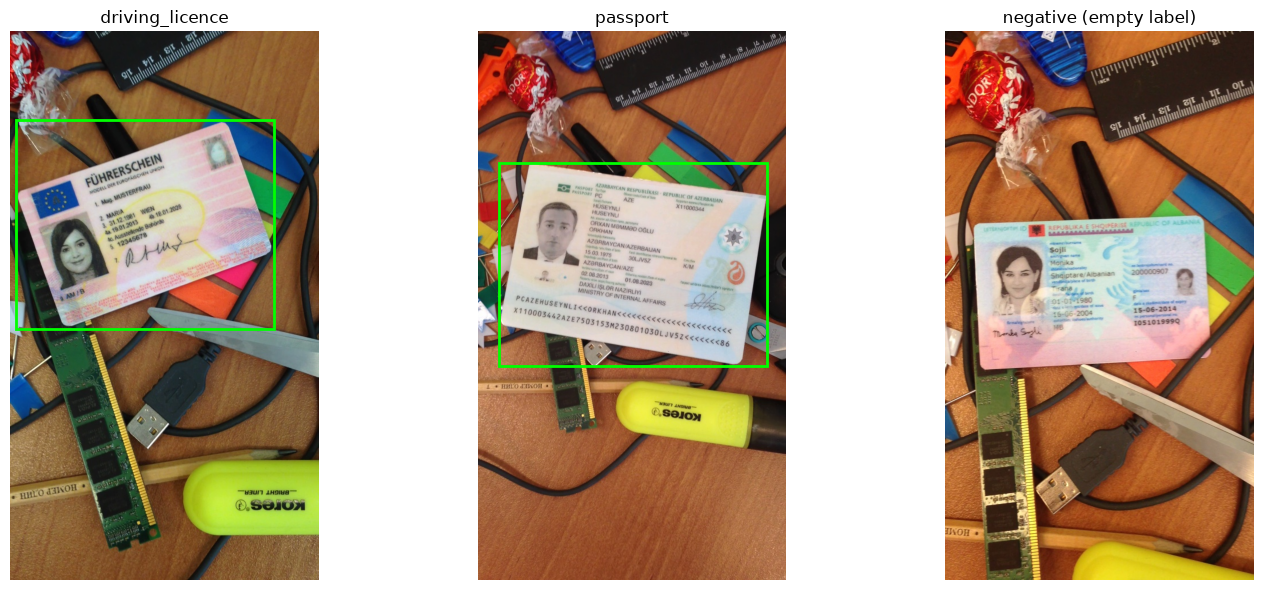

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, cls in zip(axes, (0, 1, None)):
    rec = next(r for r in records if r['split'] == 'train' and r['class'] == cls)
    image = cv2.cvtColor(cv2.imread(rec['image']), cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    if cls is not None:
        _, cx, cy, bw, bh = map(float, Path(rec['label']).read_text().split())
        h, w = image.shape[:2]
        ax.add_patch(Rectangle(((cx - bw/2) * w, (cy - bh/2) * h), bw * w, bh * h, fill=False, edgecolor='lime', linewidth=2))
    ax.set_title(NAMES.get(cls, 'negative (empty label)'))
    ax.axis('off')
plt.tight_layout()
plt.show()
